# 02 — Composition by subtype and lineage

GC content and the four GC dinucleotide O/E ratios, compared between RSV-A and RSV-B and across lineages.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath("../src"))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 120)
from rsv import io, composition


In [2]:
d = pd.read_csv("../data/processed/rsv_features.tsv", sep="\t")
FEATS = ["gc_content","oe_CG","oe_GC","oe_GG","oe_CC"]
d.groupby("Subtype")[FEATS].agg(["mean","std"]).round(4)

gc_content           oe_CG           oe_GC           oe_GG           oe_CC        
              mean     std    mean     std    mean     std    mean     std    mean     std
Subtype                                                                                   
A           0.3344  0.0011  0.2361  0.0081  0.9956  0.0074  1.1303  0.0084  1.0635  0.0085
B           0.3364  0.0006  0.2408  0.0073  1.0864  0.0067  1.0535  0.0076  1.0083  0.0098

### A vs B: is the difference significant? (Mann–Whitney U)

In [3]:
from scipy.stats import mannwhitneyu
for f in FEATS:
    a=d[d.Subtype=="A"][f]; b=d[d.Subtype=="B"][f]
    u,p = mannwhitneyu(a,b)
    print(f"{f:10s} A={a.mean():.4f} B={b.mean():.4f}  p={p:.2e}")

gc_content A=0.3344 B=0.3364  p=0.00e+00
oe_CG      A=0.2361 B=0.2408  p=0.00e+00
oe_GC      A=0.9956 B=1.0864  p=0.00e+00
oe_GG      A=1.1303 B=1.0535  p=0.00e+00
oe_CC      A=1.0635 B=1.0083  p=0.00e+00


### Composition across the most common lineages

In [4]:
top = (d.groupby(["Subtype","Lineage"]).size().rename("n").reset_index()
        .sort_values("n",ascending=False).groupby("Subtype").head(8))
lin = d.merge(top[["Subtype","Lineage"]], on=["Subtype","Lineage"])
summ = lin.groupby(["Subtype","Lineage"])[FEATS+["gc_content"]].mean()
summ = lin.groupby(["Subtype","Lineage"]).agg(n=("gc_content","size"),
        gc=("gc_content","mean"), oe_CG=("oe_CG","mean")).round(4)
summ.to_csv("../results/composition_by_lineage_summary.tsv", sep="\t")
summ

n      gc   oe_CG
Subtype Lineage                        
A       A.D        1377  0.3339  0.2379
        A.D.1      1196  0.3350  0.2390
        A.D.1.5     998  0.3351  0.2333
        A.D.1.6     636  0.3348  0.2402
        A.D.3      2451  0.3336  0.2367
        A.D.3.3     528  0.3331  0.2269
        A.D.5.1     918  0.3353  0.2351
        A.D.5.2    1523  0.3352  0.2319
B       B.D         346  0.3371  0.2420
        B.D.4.1     912  0.3363  0.2330
        B.D.4.1.1  3237  0.3366  0.2389
        B.D.E.1    9219  0.3364  0.2433
        B.D.E.1.1   463  0.3360  0.2506
        B.D.E.1.2  1344  0.3360  0.2395
        B.D.E.4     717  0.3359  0.2278
        B.D.E.5     276  0.3363  0.2296

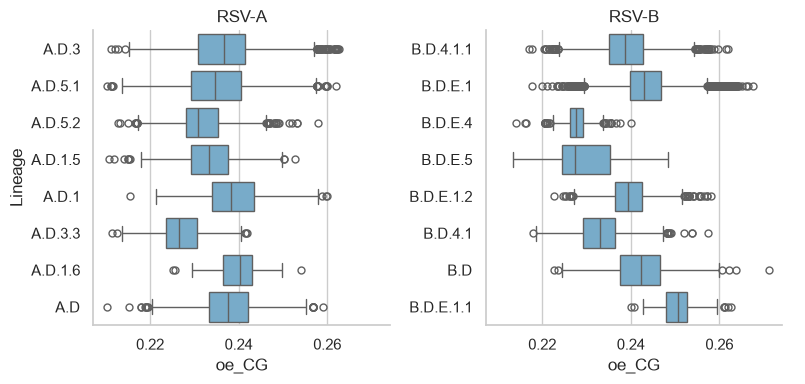

In [5]:
g = sns.catplot(data=lin, x="oe_CG", y="Lineage", col="Subtype", kind="box",
    sharey=False, height=4, aspect=1, color="#6baed6")
g.set_titles("RSV-{col_name}"); plt.show()